# [17.3] Fine-Tuning Diffs and Capability Emergence (exercises)

> **Colab:
> [exercises](https://colab.research.google.com/github/shinobiultra/ARENA_3.0_Extended/blob/main/chapter17_training_dynamics/exercises/part3_finetuning_diffs_emergence/17.3_Fine-Tuning_Diffs_and_Capability_Emergence_exercises.ipynb) |
> [solutions](https://colab.research.google.com/github/shinobiultra/ARENA_3.0_Extended/blob/main/chapter17_training_dynamics/exercises/part3_finetuning_diffs_emergence/17.3_Fine-Tuning_Diffs_and_Capability_Emergence_solutions.ipynb)**

This section is part of the ARENA extension. The solutions notebook is saved with all of its outputs, so you can use it as a reference for what every cell should produce.

You can collapse each section so only the headers are visible, by clicking the arrow symbol on the left hand side of the markdown header cells.

<img src="https://raw.githubusercontent.com/info-arena/ARENA_img/main/misc/headers/header-12.png" width="350">

# Introduction

By the end of this notebook, you will have shown that a discrete capability jump can arise from a smooth component update, using paired checkpoint differences, sparse reconstruction and causal component replacement against a nuisance-component control.

Here is a small capability puzzle. An input contains three signs, $(a,b,c)\in\{-1,+1\}^3$. Predict whether $a$ and $b$ agree: the target sign is $y=ab$. A model initially prefers the individual signs; a later version uses their product. If accuracy jumps between two saved versions, did a new feature suddenly appear, did an existing feature gain readout weight, or did the scoring threshold hide a gradual change?

We will inspect every one of the eight inputs, so this is an **exhaustive finite-domain analytic study**, with no train/test claim. Checkpoints are specified by an interpolation coefficient, not obtained by fine-tuning. That controlled setting makes the causal question exactly answerable while exposing traps that matter when comparing real Pythia checkpoints or before/after a fine-tune.

Here you build the diffing, paired sparse-coding and patching tools that a pinned native study must supply with real arrays. Prerequisites: matrix multiplication, least squares, [1.2] activation patching. Allow 90–120 minutes.

## Content & Learning Objectives

### 1️⃣ What changed?

> ##### Learning Objectives
>
> - Compute parameter and activation differences with matched checkpoint identities and example ordering.

### 2️⃣ Shared and changed features

> ##### Learning Objectives
>
> - Infer a sparse shared code for paired activations using a fixed dictionary, and measure reconstruction failure.

### 3️⃣ When does the answer flip?

> ##### Learning Objectives
>
> - Separate continuous logit margins from a discrete capability score across constructed checkpoints.

### 4️⃣ Which component caused the change?

> ##### Learning Objectives
>
> - Replace one component at a time and compare task improvement to an equal-size nuisance intervention.

## Setup code

Use the repository environment. This study edition needs only NumPy and Matplotlib, runs on CPU, and downloads nothing.

In [ ]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from itertools import product
chapter = "chapter17_training_dynamics"
section = "part3_finetuning_diffs_emergence"
root_dir = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / chapter).exists())
exercises_dir = root_dir / chapter / "exercises"
if str(exercises_dir) not in sys.path:
    sys.path.append(str(exercises_dir))
import part3_finetuning_diffs_emergence.tests as tests
import part3_finetuning_diffs_emergence.utils as utils
MAIN = __name__ == "__main__"
np.set_printoptions(precision=4, suppress=True)

# 1️⃣ What changed?

> ##### Learning Objectives
>
> - Compute parameter and activation differences with matched checkpoint identities and example ordering.

Checkpoint differencing requires the same parameter name, tensor axes, vocabulary and basis. Subtracting unrelated initializations may measure a coordinate choice. Likewise, activation row $i$ must correspond to the same input and token position in both checkpoints.

For this organism the hidden vector is $h=(a,b,ab,c)$ and the scalar score is $s=h^\top w$. A positive score predicts $+1$. The signed margin $m=ys$ is positive exactly when the prediction is correct (we count zero as incorrect to make the tie rule explicit). Our constructed checkpoints will change both the product feature’s amplitude and its output weight. We keep those two operations separate so you can determine what each diff measures.

### Exercise - implement `parameter_diff`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Subtract matching before/after parameter dictionaries. Require identical keys and shapes; never silently omit a missing tensor. Return new arrays.

In [ ]:
def parameter_diff(before, after):
    raise NotImplementedError()


tests.test_parameter_diff(parameter_diff)

<details><summary>Hint</summary>

Check identities before numerical subtraction.

</details>

<details><summary>Expected output</summary>

<pre style="white-space: pre-wrap">w: [1,2] → [3,1] gives delta [2,-1].</pre>

</details>


<details><summary>Solution</summary>

```python
def parameter_diff(before, after):
    if before.keys() != after.keys():
        raise ValueError("Checkpoint keys differ")
    if any(before[k].shape != after[k].shape for k in before):
        raise ValueError("Checkpoint shapes differ")
    return {k: after[k] - before[k] for k in before}
```
</details>

### Exercise - implement `relative_change`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Return ||after-before||F / ||before||F. A zero reference has no relative scale: return NaN, including the both-zero case.

In [ ]:
def relative_change(before, after):
    raise NotImplementedError()


tests.test_relative_change(relative_change)

<details><summary>Hint</summary>

Do not hide an undefined relative change behind an arbitrary epsilon.

</details>

<details><summary>Expected output</summary>

<pre style="white-space: pre-wrap">[3,4] → [6,8] gives relative change 1; zero reference gives NaN.</pre>

</details>


<details><summary>Solution</summary>

```python
def relative_change(before, after):
    denom = np.linalg.norm(before)
    return float(np.linalg.norm(after-before)/denom) if denom else float("nan")
```
</details>

### Exercise - implement `activation_difference`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Align paired [examples,features] arrays by exact ordered example IDs, then return after-before. Reject a reordered or duplicated ID list rather than pretending rows match.

In [ ]:
def activation_difference(before, after, before_ids, after_ids):
    raise NotImplementedError()


tests.test_activation_difference(activation_difference)

<details><summary>Hint</summary>

A wrong row order creates a large but meaningless diff.

</details>

<details><summary>Expected output</summary>

<pre style="white-space: pre-wrap">Matched arrays separated by 2 give a matrix of 2s; reordered IDs fail.</pre>

</details>


<details><summary>Solution</summary>

```python
def activation_difference(before, after, before_ids, after_ids):
    if list(before_ids) != list(after_ids) or len(set(before_ids)) != len(before_ids):
        raise ValueError("Require matching unique ordered examples")
    if before.shape != after.shape or len(before_ids) != len(before):
        raise ValueError("Paired activation shape mismatch")
    return after-before
```
</details>

In [ ]:
inputs = np.array(list(product([-1.,1.],repeat=3)))
a,b,c = inputs.T
targets = a*b
base_hidden = np.column_stack([a,b,.25*a*b,c])
late_hidden = np.column_stack([a,b,a*b,c])
example_ids = [f"{int(x):+d}/{int(y):+d}/{int(z):+d}" for x,y,z in inputs]
delta_hidden = activation_difference(base_hidden,late_hidden,example_ids,example_ids)
print("input         target   delta(product feature)")
for eid,y,d in zip(example_ids,targets,delta_hidden[:,2]):
    print(eid, f"{y:+.0f}", f"{d:+.2f}")

<details><summary>Help - how should I interpret this?</summary>

Only the product-feature column changes, by +.75 when the target is +1 and -.75 when it is -1. The input coordinates and nuisance sign are unchanged. This is a known-basis organism: a real model diff must establish feature alignment rather than assume neuron indices mean the same thing.

</details>

## Summary of 1️⃣

Parameter movement is not behavior. Row-aligned activation differences tell us which finite examples changed, but still do not establish whether the readout uses that change.

# 2️⃣ Shared and changed features

> ##### Learning Objectives
>
> - Infer a sparse shared code for paired activations using a fixed dictionary, and measure reconstruction failure.

A crosscoder reads activations from multiple sites and reconstructs multiple sites from a shared sparse latent. We will build the **paired reconstruction calculation**, with an explicitly supplied dictionary, rather than pretend to discover semantic features with a trained crosscoder.

Concatenate matched activations $X=[H_0\;H_1]\in\mathbb R^{n\times 2d}$. For dictionary rows $D\in\mathbb R^{k\times 2d}$ infer signed codes $Z$ by minimizing $\frac12\|ZD-X\|_F^2+\lambda\|Z\|_1$. This convex fixed-dictionary coding problem admits iterative soft thresholding: $Z\leftarrow S_{\eta\lambda}(Z-\eta(ZD-X)D^\top)$ with $\eta\le1/\|D\|_2^2$. Learned crosscoders have additional encoder, decoder and optimization choices; signed ISTA here is a transparent bridge, not their full implementation.

Our dictionary contains paired axes for the known components. The product axis has unequal before/after amplitude, so the shared latent can explain a changed readout channel without needing unrelated dictionaries at each checkpoint. A deliberately wrong pairing is our reconstruction control.

### Exercise - implement `paired_stack`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Concatenate matched [n,d] before/after activations along features to [n,2d]. Require equal shapes. Do not stack examples.

In [ ]:
def paired_stack(before, after):
    raise NotImplementedError()


tests.test_paired_stack(paired_stack)

<details><summary>Hint</summary>

The same latent code reconstructs both checkpoint feature blocks.

</details>

<details><summary>Expected output</summary>

<pre style="white-space: pre-wrap">[[1,2]] and [[3,4]] become [[1,2,3,4]].</pre>

</details>


<details><summary>Solution</summary>

```python
def paired_stack(before, after):
    if before.shape != after.shape:
        raise ValueError("Paired activations must have equal shapes")
    return np.concatenate([before,after],axis=1)
```
</details>

### Exercise - implement `soft_threshold`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Implement signed soft thresholding Sλ(x)=sign(x) max(|x|-λ,0), elementwise. Reject negative penalties.

In [ ]:
def soft_threshold(x, penalty):
    raise NotImplementedError()


tests.test_soft_threshold(soft_threshold)

<details><summary>Hint</summary>

Negative codes are allowed in this teaching variant. ReLU alone is the wrong proximal operator.

</details>

<details><summary>Expected output</summary>

<pre style="white-space: pre-wrap">[-2,-.2,0,.2,2] with penalty .5 gives [-1.5,0,0,0,1.5].</pre>

</details>


<details><summary>Solution</summary>

```python
def soft_threshold(x, penalty):
    if penalty < 0:
        raise ValueError("Penalty must be nonnegative")
    return np.sign(x)*np.maximum(np.abs(x)-penalty,0)
```
</details>

### Exercise - implement `infer_codes`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Run fixed-dictionary ISTA from zeros for a fixed number of iterations. X is [n,m], dictionary [k,m]. Use the spectral-norm step and return [n,k]. A zero dictionary returns zero codes.

In [ ]:
def infer_codes(x, dictionary, penalty=.05, steps=200):
    raise NotImplementedError()


tests.test_infer_codes(infer_codes)

<details><summary>Hint</summary>

The gradient has shape [n,k]. For D=2I the analytic solution is soft_threshold(2X,λ)/4.

</details>

<details><summary>Expected output</summary>

<pre style="white-space: pre-wrap">For X=[2,-1,.01], D=I, λ=.1: codes [1.9,-.9,0].</pre>

</details>


<details><summary>Solution</summary>

```python
def infer_codes(x, dictionary, penalty=.05, steps=200):
    lipschitz = np.linalg.norm(dictionary,ord=2)**2
    z = np.zeros((len(x),len(dictionary)))
    if lipschitz == 0:
        return z
    eta = 1/lipschitz
    for _ in range(steps):
        grad = (z@dictionary-x)@dictionary.T
        z = soft_threshold(z-eta*grad, eta*penalty)
    return z
```
</details>

### Exercise - implement `reconstruct_pair`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Reconstruct ZD and split the feature columns into two equal blocks. Return both [n,d] reconstructions.

In [ ]:
def reconstruct_pair(codes, dictionary):
    raise NotImplementedError()


tests.test_reconstruct_pair(reconstruct_pair)

<details><summary>Hint</summary>

Split reconstructed columns, not latent columns.

</details>

<details><summary>Expected output</summary>

<pre style="white-space: pre-wrap">Codes [2,3] and paired diagonal dictionary give [2,3] and [8,15].</pre>

</details>


<details><summary>Solution</summary>

```python
def reconstruct_pair(codes, dictionary):
    joint = codes@dictionary
    if joint.shape[1] % 2:
        raise ValueError("Paired feature blocks must have equal width")
    return tuple(np.split(joint,2,axis=1))
```
</details>


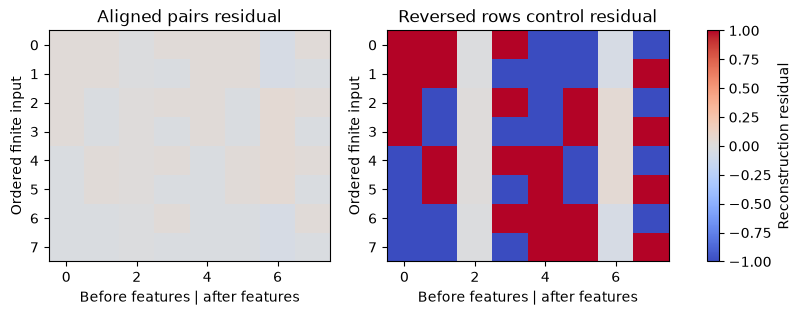

In [ ]:
joint = paired_stack(base_hidden,late_hidden)
dictionary = np.concatenate([np.diag([1,1,.25,1]), np.eye(4)],axis=1)
codes = infer_codes(joint,dictionary,penalty=.05)
rec0,rec1 = reconstruct_pair(codes,dictionary)
wrong_joint = paired_stack(base_hidden,late_hidden[::-1])
wrong_codes = infer_codes(wrong_joint,dictionary,penalty=.05)
print("paired reconstruction MSE",round(float(np.mean((codes@dictionary-joint)**2)),6))
print("wrong-pair reconstruction MSE",round(float(np.mean((wrong_codes@dictionary-wrong_joint)**2)),6))
fig,axes=plt.subplots(1,2,figsize=(10,3))
for ax,arr,title in zip(axes,[codes@dictionary-joint,wrong_codes@dictionary-wrong_joint],["Aligned pairs residual", "Reversed rows control residual"]):
    im=ax.imshow(arr,vmin=-1,vmax=1,cmap="coolwarm",aspect="auto")
    ax.set(title=title,xlabel="Before features | after features",ylabel="Ordered finite input")
fig.colorbar(im,ax=list(axes),label="Reconstruction residual")
plt.show()

<details><summary>Help - how should I interpret this?</summary>

The correct paired dictionary reconstructs both sites with small shrinkage residuals. Reversing the after rows violates the dictionary’s assumed relationship: a shared code cannot explain both signs simultaneously. This detects a data-alignment problem, not learned semantic feature validity. With a more flexible dictionary even the wrong pairing could reconstruct; reconstruction alone does not certify causal meaning.

</details>

## Summary of 2️⃣

You implemented a sparse inference objective and tested its exact orthogonal-dictionary solution. A learned crosscoder would additionally need train/DEV feature selection, decoder normalization, reconstruction baselines and causal feature interventions.

# 3️⃣ When does the answer flip?

> ##### Learning Objectives
>
> - Separate continuous logit margins from a discrete capability score across constructed checkpoints.

An exact-match capability is a thresholded measurement. If every model margin grows smoothly, accuracy can still change in discrete steps when different examples cross zero. Inspect the full margin distribution, not only its mean or accuracy.

At coordinate $g\in[0,1]$, set $H_g[:,2]=(.25+.75g)ab$ and $w_g=(.4,.4,2g,.15)$. Score $s_g=H_gw_g$. This is a **chosen smooth path through models**. It is not evidence that training follows the path, that capabilities are never abrupt, or that a given Pythia capability emerges at these coordinates. Here it supplies an exactly controllable counterexample to one naive inference from a staircase plot.

### Exercise - implement `signed_margins`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Return signed margins y*(H@w), one per example. The target signs must be ±1.

In [ ]:
def signed_margins(hidden, readout, targets):
    raise NotImplementedError()


tests.test_signed_margins(signed_margins)

<details><summary>Hint</summary>

The score itself is not a margin until multiplied by the correct target sign.

</details>

<details><summary>Expected output</summary>

<pre style="white-space: pre-wrap">Scores [4,1] and labels [1,-1] give margins [4,-1].</pre>

</details>


<details><summary>Solution</summary>

```python
def signed_margins(hidden, readout, targets):
    if not np.isin(targets,[-1,1]).all():
        raise ValueError("Use signed labels")
    return targets*(hidden@readout)
```
</details>

### Exercise - implement `capability_accuracy`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Return the fraction of strictly positive signed margins. A zero margin is counted as incorrect under our frozen tie rule.

In [ ]:
def capability_accuracy(margins):
    raise NotImplementedError()


tests.test_capability_accuracy(capability_accuracy)

<details><summary>Hint</summary>

Use >0, not >=0.

</details>

<details><summary>Expected output</summary>

<pre style="white-space: pre-wrap">Margins [-1,0,1,2] give accuracy .5.</pre>

</details>


<details><summary>Solution</summary>

```python
def capability_accuracy(margins):
    return float(np.mean(np.asarray(margins)>0))
```
</details>

### Exercise - implement `threshold_crossing`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Return the earliest provided coordinate reaching a prespecified capability threshold; None means it never reaches it. Do not interpolate across a discrete accuracy jump.

In [ ]:
def threshold_crossing(coordinates, accuracies, threshold=.9):
    raise NotImplementedError()


tests.test_threshold_crossing(threshold_crossing)

<details><summary>Hint</summary>

The checkpoint spacing bounds temporal resolution even for real optimization steps.

</details>

<details><summary>Expected output</summary>

<pre style="white-space: pre-wrap">[.5,.75,1] at [0,.2,.5] first reaches .9 at .5.</pre>

</details>


<details><summary>Solution</summary>

```python
def threshold_crossing(coordinates, accuracies, threshold=.9):
    hits=np.flatnonzero(np.asarray(accuracies)>=threshold)
    return coordinates[int(hits[0])] if len(hits) else None
```
</details>


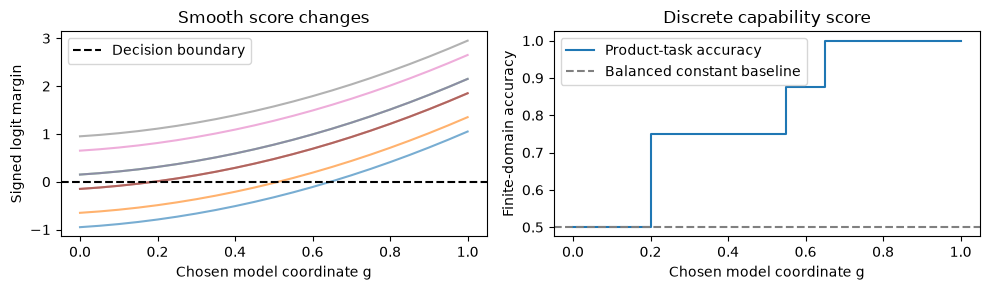

In [ ]:
coordinates = np.linspace(0,1,21)
history, margin_history = [], []
for g in coordinates:
    hidden=np.column_stack([a,b,(.25+.75*g)*a*b,c])
    readout=np.array([.4,.4,2*g,.15])
    margins=signed_margins(hidden,readout,targets)
    history.append(capability_accuracy(margins));margin_history.append(margins)
margin_history=np.array(margin_history)
print("accuracy at g=0,.25,.5,.75,1:",np.array(history)[[0,5,10,15,20]])
print("first coordinate at accuracy >= .9:",threshold_crossing(coordinates,history))
fig,axes=plt.subplots(1,2,figsize=(10,3))
axes[0].plot(coordinates,margin_history,alpha=.6)
axes[0].axhline(0,color="black",ls="--",label="Decision boundary")
axes[0].set(xlabel="Chosen model coordinate g",ylabel="Signed logit margin",title="Smooth score changes");axes[0].legend()
axes[1].step(coordinates,history,where="post",label="Product-task accuracy")
axes[1].axhline(.5,color="gray",ls="--",label="Balanced constant baseline")
axes[1].set(xlabel="Chosen model coordinate g",ylabel="Finite-domain accuracy",title="Discrete capability score");axes[1].legend()
utils.finish_figure(fig)

<details><summary>Help - how should I interpret this?</summary>

The line plot and staircase describe the same eight examples. Accuracy discards the size of a correct or incorrect margin. Requiring 90% on eight cases means requiring all eight, so the threshold choice and example count jointly affect the apparent onset. Checkpoint density would also affect onset resolution. None of this supplies a real training trajectory.

</details>

## Summary of 3️⃣

A capability plot needs continuous metrics, denominator, tie rule and a predeclared onset definition. A discrete jump alone does not identify a new mechanism.

# 4️⃣ Which component caused the change?

> ##### Learning Objectives
>
> - Replace one component at a time and compare task improvement to an equal-size nuisance intervention.

Replacing one late component by its early value tests whether the late component is needed **in the late context**. Restoring one early component tests sufficiency **in the early context**. Interactions and compensation mean those two effects need not agree, and one-component effects do not automatically sum to the total change.

Define a component contribution as $C_{ij}=H_{ij}w_j$. Replacement acts on this contribution directly; this is an exact additive model organism. In a transformer, weight replacement can alter downstream activations, so rerun the complete forward pass and record whether your intervention replaces weights, cached activations or outputs.

### Exercise - implement `component_patch`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Given recipient and donor contribution arrays [n,components], return recipient total scores after replacing one component column from donor. Leave both arrays unchanged.

In [ ]:
def component_patch(recipient, donor, component):
    raise NotImplementedError()


tests.test_component_patch(component_patch)

<details><summary>Hint</summary>

Copy before assignment. The output is total score, not patched contributions.

</details>

<details><summary>Expected output</summary>

<pre style="white-space: pre-wrap">Replacing column0 of [[1,2],[3,4]] with [9,7] yields totals [11,11].</pre>

</details>


<details><summary>Solution</summary>

```python
def component_patch(recipient, donor, component):
    patched=recipient.copy()
    patched[:,component]=donor[:,component]
    return patched.sum(axis=1)
```
</details>

### Exercise - implement `patch_effects`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Return late accuracy minus patched-late accuracy for each component, using early contributions as donor. The result is a necessity loss in accuracy units.

In [ ]:
def patch_effects(early, late, targets):
    raise NotImplementedError()


tests.test_patch_effects(patch_effects)

<details><summary>Hint</summary>

Use the same label vector and tie rule in clean and patched conditions.

</details>

<details><summary>Expected output</summary>

<pre style="white-space: pre-wrap">Only useful component: necessity losses [1,0].</pre>

</details>


<details><summary>Solution</summary>

```python
def patch_effects(early, late, targets):
    clean=capability_accuracy(targets*late.sum(axis=1))
    return np.array([clean-capability_accuracy(targets*component_patch(late,early,j)) for j in range(late.shape[1])])
```
</details>

Which of the four columns will have the largest necessity effect at g=1? Will its activation-difference norm or its weight difference alone give the same causal answer?


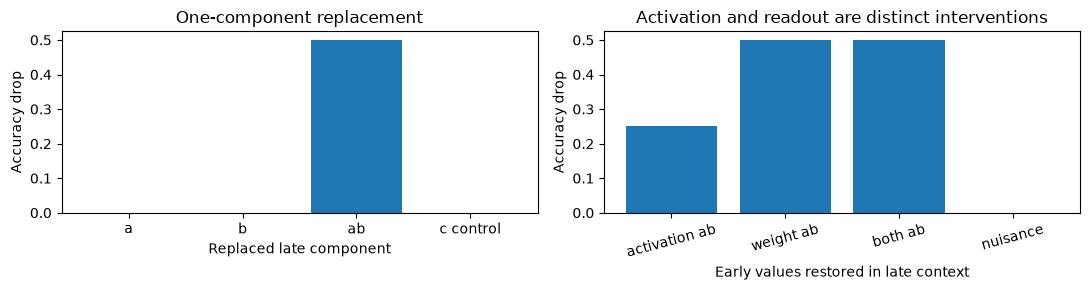

In [ ]:
early_readout=np.array([.4,.4,0.,.15]); late_readout=np.array([.4,.4,2.,.15])
early_contrib=base_hidden*early_readout;late_contrib=late_hidden*late_readout
effects=patch_effects(early_contrib,late_contrib,targets)
print("necessity accuracy losses [a,b,product,nuisance]:",effects)
print("late accuracy:",capability_accuracy(targets*late_contrib.sum(axis=1)))
fig,axes=plt.subplots(1,2,figsize=(11,3))
axes[0].bar(["a","b","ab","c control"],effects)
axes[0].set(xlabel="Replaced late component",ylabel="Accuracy drop",title="One-component replacement")
axes[1].bar(["activation ab","weight ab","both ab","nuisance"],[
 capability_accuracy(signed_margins(late_hidden,late_readout,targets))-capability_accuracy(signed_margins(base_hidden,late_readout,targets)),
 capability_accuracy(signed_margins(late_hidden,late_readout,targets))-capability_accuracy(signed_margins(late_hidden,early_readout,targets)),effects[2],effects[3]])
axes[1].set(xlabel="Early values restored in late context",ylabel="Accuracy drop",title="Activation and readout are distinct interventions")
axes[1].tick_params(axis="x",rotation=15)
utils.finish_figure(fig)

<details><summary>Reference measurement</summary>

<pre style="white-space: pre-wrap">aligned paired reconstruction MSE .000763
reversed-pair reconstruction MSE .750294
accuracy at g=0,.25,.5,.75,1: [.5,.75,.75,1,1]
first saved coordinate at accuracy ≥ .9: .65
late accuracy 1.0
component necessity losses [a,b,ab,c]: [0,0,.5,0]</pre>

</details>

## Try it yourself

Increase the nuisance readout from .15 to 1.5 in **both** early and late models. Forecast whether the product component still gives perfect late accuracy, then rerun the controlled patch chart. This changes the competing computation, rather than merely replicating the same fixture with a new seed.

In [ ]:
nuisance_weight=1.5
play_early=early_contrib.copy();play_late=late_contrib.copy()
play_early[:,3]=c*nuisance_weight;play_late[:,3]=c*nuisance_weight
print("changed-condition late accuracy",capability_accuracy(targets*play_late.sum(axis=1)))
print("changed-condition patch losses",patch_effects(play_early,play_late,targets))

## Interpreting the result

The product component improves the task because it changes signed margins in the correct direction for every input. The nuisance component can have a large parameter norm and no checkpoint difference; if it is already present in both checkpoints, replacing it with its early value is a no-op. This is why a matched unchanged-component control is useful, and why norm rankings are not causal attribution.

### Native fine-tuning and Pythia bridge

For each real checkpoint, pin model/tokenizer revision, fine-tune adapter merge state, parameter names, cached sites and ordered prompts. Save logits and continuous target margins on a frozen task with paraphrase and answer-frequency controls. Use `parameter_diff` and row-checked `activation_difference` first. A learned paired sparse dictionary additionally needs its own TRAIN/DEV data, decoder normalization, feature stability and reconstruction baselines; our fixed dictionary does not establish feature discovery.

Test an attributed layer/head by rerunning exact before/after component replacements. Include equal-size unrelated components and both noising and denoising directions. A small factual task can show memorization, prompting sensitivity or output bias; a claim of general capability emergence requires a broader frozen evaluation. These are pending native experiments, not gaps filled by the analytic organism.

**Anomaly hunt:** suppose the largest weight delta has zero patch effect. Is the feature inactive, redundant, or canceled downstream? Propose one intervention that distinguishes the possibilities.

## Summary of 4️⃣

A change is causally important only relative to an intervention, data, recipient context and metric. Your necessity chart states all four.

# ☆ Bonus

## Limitations

No actual fine-tune, Pythia activations or trained crosscoder is run. The finite product task and smooth checkpoint path are constructed and exhaustively observed. Sparse codes use a supplied dictionary; neuron alignment is known by design. Native attribution, feature discovery and capability-emergence claims remain unqualified.

## Further Reading

- [Biderman et al.: Pythia](https://arxiv.org/abs/2304.01373) — checkpoint identities and controlled training-data order.
- [Lindsey et al.: Sparse Crosscoders for Cross-Layer Features and Model Diffing](https://transformer-circuits.pub/2024/crosscoders/index.html) — preliminary research update on learned shared features; our fixed signed coding problem is a teaching bridge.
- [Schaeffer et al.: Are Emergent Abilities of Large Language Models a Mirage?](https://arxiv.org/abs/2304.15004) — metric choice can produce apparent emergence; it does not settle every capability claim.